# Proyek Analisis Data: Air Quality Dataset
- **Nama:** Rizky Wahyu Dina Putri
- **Email:** rizkydinap@gmail.com
- **ID Dicoding:** rizkydinap

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Dari 12 stasiun pemantauan di Beijing, stasiun mana yang memiliki rata-rata PM2.5 harian tertinggi dan terendah selama 1 Maret 2013 – 28 Februari 2017, dan berapa persen hari di setiap stasiun yang rata-rata PM2.5-nya melampaui 75 µg/m³, sehingga wilayah prioritas pengendalian polusi dapat ditentukan?
- **Pertanyaan 2:** Bagaimana tren rata-rata PM2.5 bulanan di Beijing selama tahun penuh 2014–2016, pada bulan apa konsentrasinya tertinggi, dan berapa selisih rata-rata musim dingin (Des–Feb) dibandingkan musim panas (Jun–Agu), sehingga waktu peringatan dini dan pembatasan emisi dapat dijadwalkan?

## Import Semua Packages/Library yang Digunakan

In [32]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Data Wrangling

### Gathering Data

#### Load df seluruh stasiun

In [33]:
files = sorted(glob.glob("data/PRSA_Data_*.csv"))
print("Jumlah berkas:", len(files))

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print("Ukuran data (baris, kolom):", df.shape)
df.head()

Jumlah berkas: 12
Ukuran data (baris, kolom): (420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:** (Opsional)
- Data terdiri dari 12 file (12 stasiun) yang digabung menjadi 420.768  baris dan 18 kolom.
- Waktu masih terpisah di kolom year, month, day, dan hour, jadi nanti perlu digabung jadi satu kolom tanggal.

### Assessing Data

#### Identifying missing value

In [34]:
missing = df.isna().sum()
missing_df = pd.DataFrame({"jumlah_missing": missing, "persen": (missing / len(df) * 100).round(2)})
missing_df[missing_df["jumlah_missing"] > 0].sort_values("jumlah_missing", ascending=False)

,jumlah_missing,persen
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


#### Identifying duplicate data

In [35]:
print("Baris duplikat (seluruh kolom):", df.duplicated().sum())
print("Duplikat per stasiun + waktu  :", df.duplicated(subset=["station", "year", "month", "day", "hour"]).sum())

Baris duplikat (seluruh kolom): 0
Duplikat per stasiun + waktu  : 0


#### Identifying invalid / inconsistent value

In [36]:
# PM2.5 adalah bagian dari PM10, sehingga PM10 seharusnya tidak lebih kecil dari PM2.5
tidak_konsisten = (df["PM10"] < df["PM2.5"])
print("Baris dengan PM10 < PM2.5:", tidak_konsisten.sum(), f"({tidak_konsisten.mean()*100:.2f}%)")
df.loc[tidak_konsisten, ["station", "year", "month", "day", "hour", "PM2.5", "PM10"]].head()

Baris dengan PM10 < PM2.5: 21312 (5.07%)


,station,year,month,day,hour,PM2.5,PM10
273,Aotizhongxin,2013,3,12,9,116.0,90.0
274,Aotizhongxin,2013,3,12,10,123.0,94.0
275,Aotizhongxin,2013,3,12,11,130.0,104.0
276,Aotizhongxin,2013,3,12,12,132.0,87.0
277,Aotizhongxin,2013,3,12,13,129.0,84.0


#### Identifying outlier dan rentang nilai

In [37]:
kolom_polutan = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
kolom_angka = kolom_polutan + ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
df[kolom_angka].describe().T

,count,mean,std,min,25%,50%,75%,max
PM2.5,412029.0,79.793428,80.822391,2.0000,20.0,55.0,111.0,999.0
PM10,414319.0,104.602618,91.772426,2.0000,36.0,82.0,145.0,999.0
SO2,411747.0,15.830835,21.650603,0.2856,3.0,7.0,20.0,500.0
NO2,408652.0,50.638586,35.127912,1.0265,23.0,43.0,71.0,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,500.0,900.0,1500.0,10000.0
O3,407491.0,57.372271,56.661607,0.2142,11.0,45.0,82.0,1071.0
TEMP,420370.0,13.538976,11.436139,-19.9000,3.1,14.5,23.3,41.6
PRES,420375.0,1010.746982,10.474055,982.4000,1002.3,1010.4,1019.0,1042.8
DEWP,420365.0,2.490822,13.793847,-43.4000,-8.9,3.1,15.1,29.1
RAIN,420378.0,0.064476,0.821004,0.0000,0.0,0.0,0.0,72.5


In [38]:
for col in kolom_polutan:
    q1, q3 = df[col].quantile([0.25, 0.75])
    batas_atas = q3 + 1.5 * (q3 - q1)
    print(f"{col:6s} outlier IQR: {(df[col] > batas_atas).sum():6d} | nilai maks: {df[col].max()}")

print("\nPM2.5 == 999 :", (df["PM2.5"] == 999).sum(), "baris")
print("CO == 10000  :", (df["CO"] == 10000).sum(), "baris")

PM2.5  outlier IQR:  19142 | nilai maks: 999.0
PM10   outlier IQR:  14658 | nilai maks: 999.0
SO2    outlier IQR:  35566 | nilai maks: 500.0
NO2    outlier IQR:   7021 | nilai maks: 290.0
CO     outlier IQR:  28054 | nilai maks: 10000.0
O3     outlier IQR:  16599 | nilai maks: 1071.0

PM2.5 == 999 : 1 baris
CO == 10000  : 56 baris


#### Identifying cakupan waktu

In [39]:
df.groupby("year").size()

,0
year,
2013,88128
2014,105120
2015,105120
2016,105408
2017,16992


**Steps to Take:**
- **Missing value:** terdapat missing value pada seluruh polutan dan variabel cuaca (terbanyak pada CO sekitar 4,9%). Data berupa deret waktu per stasiun, sehingga missing value diisi dengan **interpolasi linear per stasiun**; kolom arah angin `wd` diisi dengan nilai sebelumnya (forward fill, lalu backward fill).
- **Duplicate data:** tidak ditemukan data duplikat, sehingga tidak ada tindakan.
- **Inconsistent value:** ada 21.312 baris (sekitar 5%) dengan PM10 lebih kecil dari PM2.5, yang tidak masuk akal secara fisik. Nilai PM10 pada baris tersebut dikosongkan dan diisi ulang bersama proses interpolasi; setelah itu PM10 dipastikan tidak lebih kecil dari PM2.5.
- **Outlier:** nilai yang tampak seperti batas alat ukur (PM2.5 = 999 dan CO = 10.000) hanya segelintir baris. Outlier menurut aturan IQR memang cukup banyak, tetapi nilai tinggi pada PM2.5 umumnya mencerminkan episode polusi berat yang nyata. Karena itu outlier **tidak dihapus**.
-  **Cakupan waktu:** tahun 2013 hanya mulai dari Maret dan 2017 hanya sampai Februari. Perbandingan antar tahun dibatasi pada tahun penuh 2014-2016.


**Insight:**
- Kualitas data secara umum baik (tanpa duplikat), tetapi missing value dan inkonsistensi PM10 harus ditangani sebelum analisis.
- Keterbatasan: interpolasi pada celah data yang panjang bersifat perkiraan, jadi hasil harian sebaiknya dibaca sebagai gambaran tren, bukan nilai pengukuran persis.

### Cleaning Data

#### Fixing waktu, nilai tidak konsisten, dan missing value

In [40]:
# 1. Gabungkan kolom waktu dan urutkan
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values(["station", "datetime"]).reset_index(drop=True)

# 2. PM10 yang lebih kecil dari PM2.5 dianggap tidak valid -> dikosongkan
df.loc[df["PM10"] < df["PM2.5"], "PM10"] = np.nan

# 3. Isi missing value per stasiun
df[kolom_angka] = df.groupby("station")[kolom_angka].transform(
    lambda s: s.interpolate(method="linear", limit_direction="both")
)
df["wd"] = df.groupby("station")["wd"].transform(lambda s: s.ffill().bfill())

# 4. Interpolasi dilakukan terpisah per kolom, sehingga PM10 dipastikan tidak lebih kecil dari PM2.5
df["PM10"] = np.maximum(df["PM10"], df["PM2.5"])

print("Sisa missing value:", df.isna().sum().sum())
print("PM10 < PM2.5 setelah dibersihkan:", (df["PM10"] < df["PM2.5"]).sum())

Sisa missing value: 0
PM10 < PM2.5 setelah dibersihkan: 0


**Insight:** (Opsional)
- Setelah cleaning, tidak ada missing value tersisa dan tidak ada lagi baris dengan PM10 < PM2.5.
- Mengisi PM10 dengan interpolasi saja belum cukup karena PM10 dan PM2.5 diinterpolasi terpisah, sehingga syarat PM10 ≥ PM2.5 ditegakkan ulang di akhir.

#### Membuat data harian untuk analisis dan dashboard

In [41]:
daily = (
    df.groupby(["station", pd.Grouper(key="datetime", freq="D")])[kolom_angka]
    .mean()
    .reset_index()
    .rename(columns={"datetime": "date"})
)

daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
daily["over_75"] = daily["PM2.5"] > 75

print(daily.shape)
daily.head()

(17532, 16)


,station,date,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,year,month,over_75
0,Aotizhongxin,2013-03-01,7.125000,10.750000,11.708333,22.583333,429.166667,63.875000,1.391667,1026.875000,-18.745833,0.0,3.254167,2013,3,False
1,Aotizhongxin,2013-03-02,30.750000,42.083333,36.625000,66.666667,824.916667,29.750000,0.616667,1026.850000,-15.937500,0.0,1.479167,2013,3,False
2,Aotizhongxin,2013-03-03,76.916667,120.541667,61.291667,81.000000,1620.625000,19.125000,5.566667,1014.608333,-12.316667,0.0,1.658333,2013,3,True
3,Aotizhongxin,2013-03-04,22.708333,44.583333,22.854167,46.187500,606.250000,53.750000,9.962500,1017.650000,-11.683333,0.0,2.404167,2013,3,False
4,Aotizhongxin,2013-03-05,148.875000,183.791667,93.875000,132.833333,2357.958333,68.458333,6.291667,1010.900000,-7.525000,0.0,1.129167,2013,3,True


### Menyimpan data untuk dashboard

In [42]:
import os
os.makedirs("dashboard", exist_ok=True)

daily_out = daily.copy()
daily_out[kolom_angka] = daily_out[kolom_angka].round(2)
daily_out.to_csv("dashboard/main_data.csv", index=False)
print("main_data.csv tersimpan")

main_data.csv tersimpan


## Exploratory Data Analysis (EDA)

### Explore statistik PM2.5 per stasiun

In [43]:
stasiun_summary = (
    daily.groupby("station")
    .agg(
        rata_rata_pm25=("PM2.5", "mean"),
        median_pm25=("PM2.5", "median"),
        maks_pm25=("PM2.5", "max"),
        persen_hari_di_atas_75=("over_75", "mean"),
    )
    .sort_values("rata_rata_pm25", ascending=False)
)
stasiun_summary["persen_hari_di_atas_75"] *= 100
stasiun_summary.round(2)

,rata_rata_pm25,median_pm25,maks_pm25,persen_hari_di_atas_75
station,,,,
Dongsi,86.14,66.12,567.42,43.53
Nongzhanguan,85.08,63.29,516.06,42.78
Wanshouxigong,85.07,64.62,536.62,42.85
Gucheng,84.07,65.54,519.75,43.05
Wanliu,83.47,64.62,481.29,42.85
Guanyuan,82.90,63.83,536.08,42.16
Aotizhongxin,82.54,62.46,512.29,42.03
Tiantan,82.03,62.67,499.33,41.34
Shunyi,79.44,60.04,514.62,40.79


In [44]:
print("Rata-rata PM2.5 seluruh stasiun :", round(daily["PM2.5"].mean(), 2))
print("Persen hari di atas 75 (semua)  :", round(daily["over_75"].mean() * 100, 2), "%")

Rata-rata PM2.5 seluruh stasiun : 79.84
Persen hari di atas 75 (semua)  : 40.35 %


**Insight:**
- Stasiun dengan rata-rata tertinggi adalah **Dongsi (86,14 µg/m³)** dan terendah **Dingling (66,85 µg/m³)**, selisih sekitar 19 µg/m³.
- Secara keseluruhan, sekitar 40% hari melampaui ambang 75 µg/m³.

### Explore pola bulanan, musiman, dan tahunan

In [45]:
musim = {12: "Musim Dingin", 1: "Musim Dingin", 2: "Musim Dingin",
         3: "Musim Semi", 4: "Musim Semi", 5: "Musim Semi",
         6: "Musim Panas", 7: "Musim Panas", 8: "Musim Panas",
         9: "Musim Gugur", 10: "Musim Gugur", 11: "Musim Gugur"}
daily["musim"] = daily["month"].map(musim)

# Hanya tahun penuh 2014-2016
daily_full = daily[daily["year"].isin([2014, 2015, 2016])]

print("Rata-rata PM2.5 per tahun (tahun penuh):")
print(daily_full.groupby("year")["PM2.5"].mean().round(1))

print("\nRata-rata PM2.5 per bulan (2014-2016):")
bulanan = daily_full.groupby("month")["PM2.5"].mean().round(1)
print(bulanan)

print("\nRata-rata PM2.5 per musim (2014-2016):")
musiman = daily_full.groupby("musim")["PM2.5"].mean().round(1)
print(musiman)

Rata-rata PM2.5 per tahun (tahun penuh):
year
2014    86.2
2015    79.3
2016    72.1
Name: PM2.5, dtype: float64

Rata-rata PM2.5 per bulan (2014-2016):
month
1      87.1
2      95.9
3      91.3
4      77.1
5      57.4
6      57.9
7      72.9
8      51.1
9      56.3
10     91.7
11     99.8
12    112.2
Name: PM2.5, dtype: float64

Rata-rata PM2.5 per musim (2014-2016):
musim
Musim Dingin    98.5
Musim Gugur     82.7
Musim Panas     60.7
Musim Semi      75.2
Name: PM2.5, dtype: float64


In [46]:
pivot_bulan_tahun = daily_full.pivot_table(index="month", columns="year", values="PM2.5", aggfunc="mean").round(1)
pivot_bulan_tahun

year,2014,2015,2016
month,,,
1,98.4,96.1,66.8
2,153.8,93.1,42.8
3,95.2,86.4,92.2
4,91.8,71.8,67.6
5,62.2,55.7,54.4
6,54.4,60.7,58.7
7,89.1,61.0,68.7
8,63.2,44.3,45.8
9,66.3,48.8,54.0


**Insight:**
- Rata-rata PM2.5 tahunan turun dari 86,2 (2014) menjadi 79,3 (2015) dan 72,1 (2016).
- Bulan tertinggi adalah **Desember (112,2 µg/m³)** dan terendah **Agustus (51,1 µg/m³)**.
- Musim dingin rata-rata 98,5 µg/m³, sedangkan musim panas 60,7 µg/m³.
- Pola antar tahun tidak seragam (misalnya Februari 2014 sangat tinggi, Februari 2016 rendah), sehingga tren bulanan per tahun dipengaruhi episode cuaca tertentu.

### Explore hubungan PM2.5 dengan polutan dan cuaca

In [47]:
korelasi = daily[kolom_angka].corr()["PM2.5"].drop("PM2.5").sort_values(ascending=False)
korelasi.round(2)

,PM2.5
PM10,0.92
CO,0.82
NO2,0.72
SO2,0.50
DEWP,0.08
PRES,0.05
RAIN,-0.04
TEMP,-0.15
O3,-0.20
WSPM,-0.38


**Insight:**
- PM2.5 berkorelasi kuat positif dengan PM10 (0,92), CO (0,82), dan NO2 (0,72); polutan ini umumnya berasal dari sumber pembakaran yang sama.
- Kecepatan angin (WSPM) berkorelasi negatif (-0,38): angin yang lebih kencang cenderung menyebarkan polutan sehingga konsentrasi PM2.5 lebih rendah.
- Korelasi menunjukkan hubungan, bukan sebab-akibat.

### Explore distribusi tiap variabel (Univariate)

Ringkasan statistik

In [48]:
kolom_eda = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "WSPM"]
ringkasan_stat = daily[kolom_eda].describe().T
ringkasan_stat["skewness"] = daily[kolom_eda].skew()
ringkasan_stat.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness
PM2.5,17532.0,79.84,69.42,3.00,30.12,60.50,107.54,567.42,1.87
PM10,17532.0,107.17,76.25,4.83,50.33,89.81,140.75,584.67,1.56
SO2,17532.0,15.91,18.59,0.47,3.83,8.99,20.30,274.36,2.59
NO2,17532.0,50.60,28.25,2.00,30.42,45.66,65.04,205.38,1.02
CO,17532.0,1235.68,985.54,100.00,620.83,958.33,1495.83,9402.08,2.57
O3,17532.0,57.24,39.76,0.29,25.57,51.50,81.68,526.42,1.00
TEMP,17532.0,13.53,10.83,-15.68,3.01,15.01,23.48,32.37,-0.16
WSPM,17532.0,1.73,0.78,0.17,1.20,1.56,2.06,7.24,1.50


Histogram PM2.5, PM10, dan WSPM

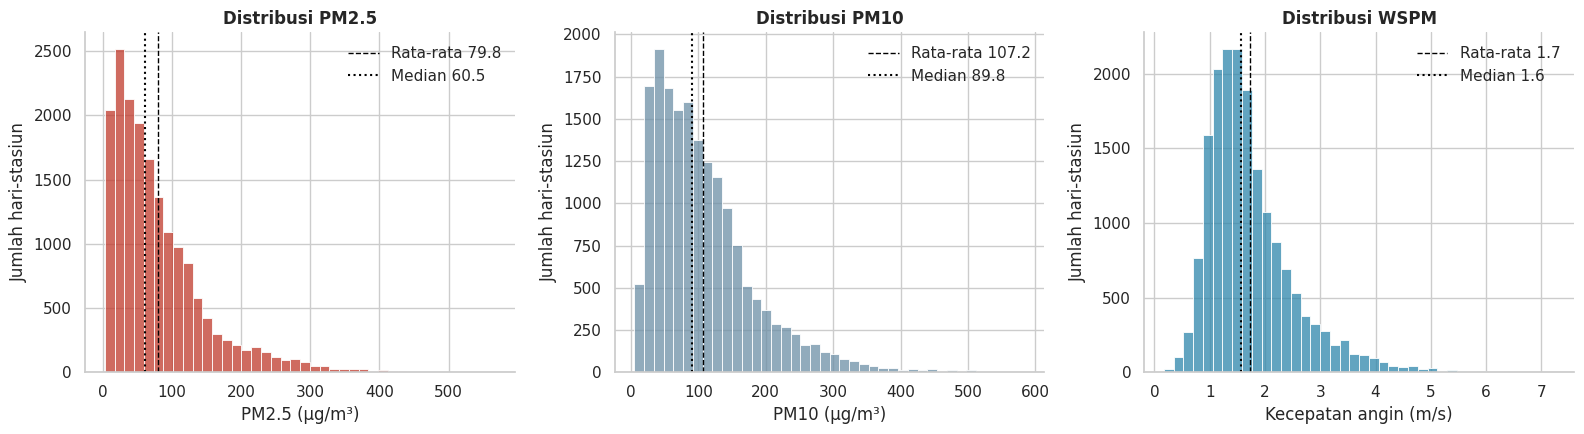

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
pengaturan = [("PM2.5", "PM2.5 (µg/m³)", "#C0392B"),
              ("PM10", "PM10 (µg/m³)", "#6C8FA6"),
              ("WSPM", "Kecepatan angin (m/s)", "#2E86AB")]

for ax, (kol, label_x, warna) in zip(axes, pengaturan):
    sns.histplot(daily[kol], bins=40, color=warna, ax=ax)
    ax.axvline(daily[kol].mean(), color="black", linestyle="--", linewidth=1, label=f"Rata-rata {daily[kol].mean():.1f}")
    ax.axvline(daily[kol].median(), color="black", linestyle=":", linewidth=1.5, label=f"Median {daily[kol].median():.1f}")
    ax.set_title(f"Distribusi {kol}", fontweight="bold")
    ax.set_xlabel(label_x)
    ax.set_ylabel("Jumlah hari-stasiun")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Boxplot tiap polutan

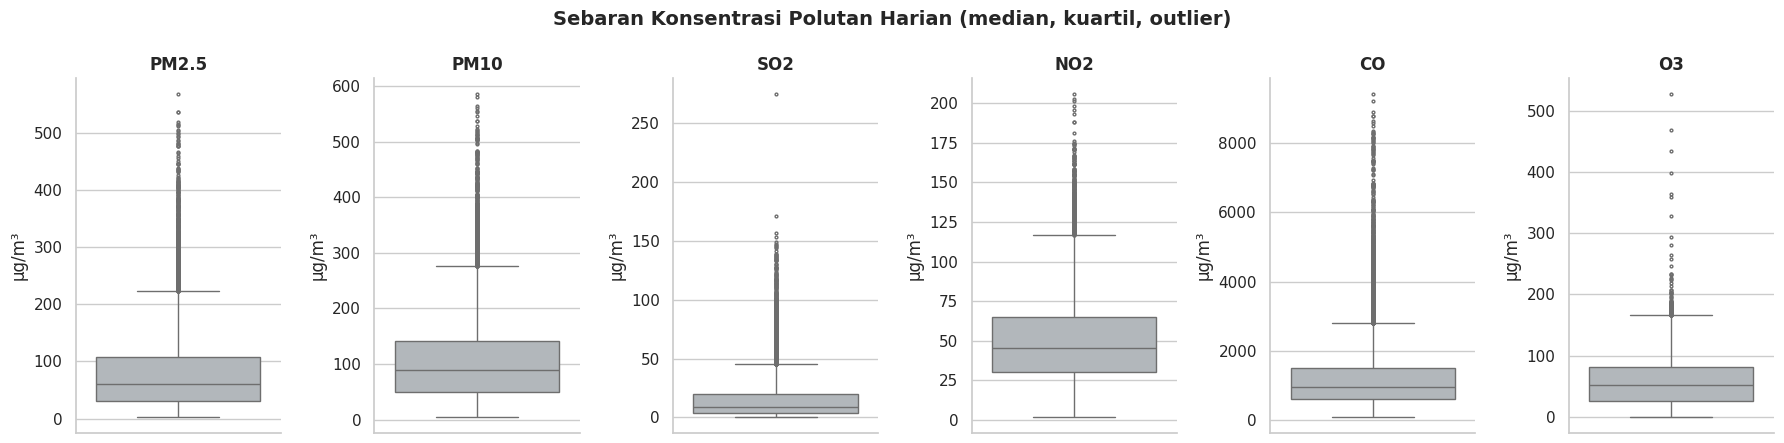

In [50]:
fig, axes = plt.subplots(1, 6, figsize=(18, 4.5))
for ax, kol in zip(axes, kolom_polutan):
    sns.boxplot(y=daily[kol], ax=ax, color="#B0B7BD", fliersize=2)
    ax.set_title(kol, fontweight="bold")
    ax.set_ylabel("µg/m³")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Sebaran Konsentrasi Polutan Harian (median, kuartil, outlier)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Rata-rata PM2.5 per tahun

In [51]:
tahunan = daily.groupby("year").agg(
    rata_rata_pm25=("PM2.5", "mean"),
    jumlah_bulan=("month", "nunique"),
).round(1)
tahunan

,rata_rata_pm25,jumlah_bulan
year,,
2013,79.8,10
2014,86.2,12
2015,79.3,12
2016,72.1,12
2017,92.4,2


In [52]:
q1, q3 = daily["PM2.5"].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
n_outlier = (daily["PM2.5"] > batas_atas).sum()
print(f"Batas atas IQR: {batas_atas:.1f} µg/m³")
print(f"Outlier PM2.5 harian: {n_outlier} dari {len(daily)} hari-stasiun ({n_outlier / len(daily) * 100:.1f}%)")

Batas atas IQR: 223.7 µg/m³
Outlier PM2.5 harian: 893 dari 17532 hari-stasiun (5.1%)


**Insight:**
- Distribusi PM2.5 dan PM10 miring ke kanan (skewness positif, masing-masing 1,87 dan 1,56): rata-rata (79,8 dan 107,2) lebih tinggi daripada median (60,5 dan 89,8), karena sebagian kecil hari memiliki konsentrasi yang sangat tinggi. Karena itu median menggambarkan hari yang umum dengan lebih baik daripada rata-rata.
- Pada data harian setelah cleaning, 893 dari 17.532 hari-stasiun (5,1%) tergolong outlier menurut aturan IQR. Angka ini berbeda dari 4,5% (19.142 baris) pada tahap Assessing karena Assessing dihitung dari data per jam sebelum cleaning, sedangkan di sini dihitung dari data harian setelah cleaning. Outlier tidak dihapus karena mencerminkan episode polusi berat yang nyata.
- Kecepatan angin harian relatif seragam di kisaran 1–2 m/s (rata-rata 1,7; median 1,6), dengan ekor tipis ke arah angin kencang.
- Rata-rata PM2.5 turun dari 86,2 (2014) ke 79,3 (2015) dan 72,1 (2016). Rata-rata 2013 (79,8) tidak memuat Januari–Februari, dan 2017 (92,4) hanya memuat Januari–Februari yang berada di musim dingin. Karena itu kedua tahun ini tidak sebanding dengan tahun penuh.

### Explore hubungan antarvariabel (Multivariate)

Correlation matrix (heatmap)

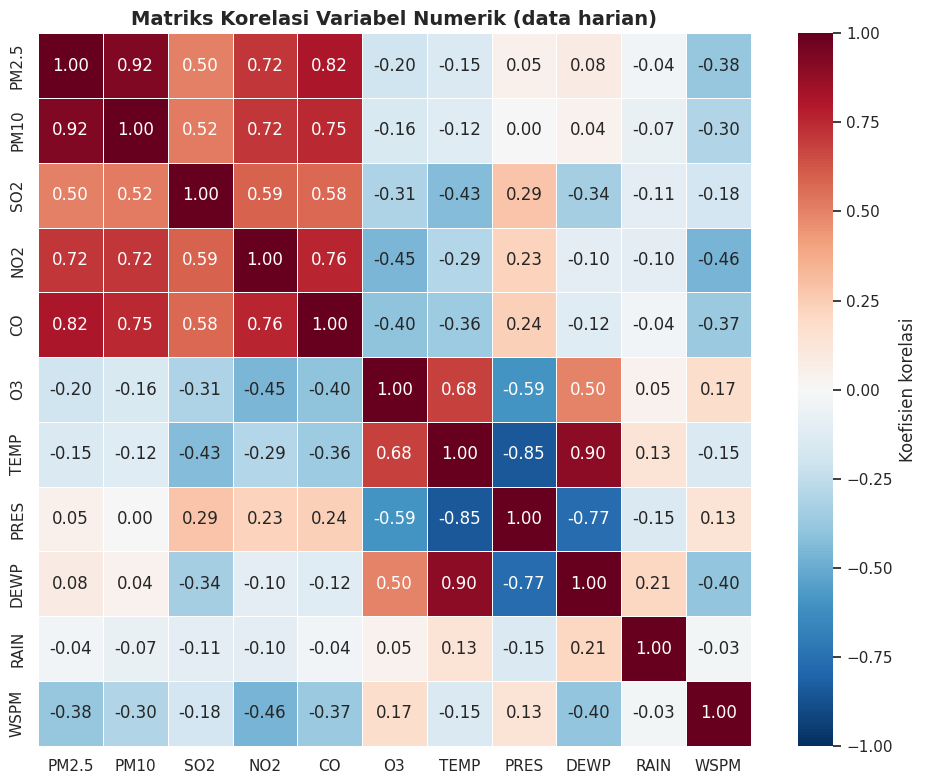

In [53]:
kolom_korelasi = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
matriks = daily[kolom_korelasi].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(matriks, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=0.5, square=True, cbar_kws={"label": "Koefisien korelasi"})
plt.title("Matriks Korelasi Variabel Numerik (data harian)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Scatter plot dan regression plot: kecepatan angin terhadap PM10 dan PM2.5

PM10: korelasi = -0.30, kemiringan garis = -29.3 µg/m³ per 1 m/s
PM2.5: korelasi = -0.38, kemiringan garis = -34.1 µg/m³ per 1 m/s


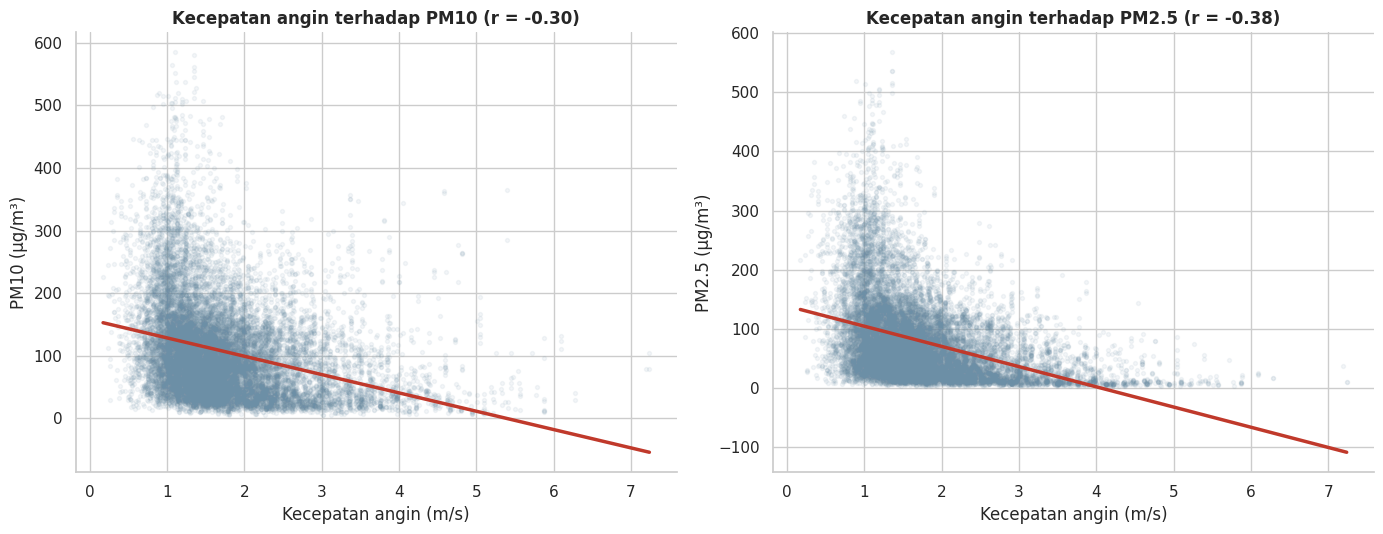

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, kol in zip(axes, ["PM10", "PM2.5"]):
    sns.regplot(data=daily, x="WSPM", y=kol, ax=ax, ci=None,
                scatter_kws={"alpha": 0.08, "s": 8, "color": "#6C8FA6"},
                line_kws={"color": "#C0392B", "linewidth": 2.5})
    r = daily["WSPM"].corr(daily[kol])
    kemiringan = np.polyfit(daily["WSPM"], daily[kol], 1)[0]
    ax.set_title(f"Kecepatan angin terhadap {kol} (r = {r:.2f})", fontweight="bold")
    ax.set_xlabel("Kecepatan angin (m/s)")
    ax.set_ylabel(f"{kol} (µg/m³)")
    ax.spines[["top", "right"]].set_visible(False)
    print(f"{kol}: korelasi = {r:.2f}, kemiringan garis = {kemiringan:.1f} µg/m³ per 1 m/s")

plt.tight_layout()
plt.show()

#### Mengelompokkan kecepatan angin

Kategori kecepatan angin

Kecepatan angin dikelompokkan menjadi tiga kategori berdasarkan **Skala Beaufort** (skala standar kekuatan angin):
- **Rendah (< 1,6 m/s):** tenang hingga angin sangat ringan (Beaufort 0–1)
- **Sedang (1,6–3,3 m/s):** angin ringan (Beaufort 2)
- **Tinggi (≥ 3,4 m/s):** angin lembut ke atas (Beaufort 3 dan seterusnya)

Skala ini dipilih karena memiliki dasar yang baku, bukan batas yang ditentukan sembarang.

In [55]:
batas_angin = [0, 1.6, 3.4, np.inf]
label_angin = ["Rendah (<1,6 m/s)", "Sedang (1,6–3,3 m/s)", "Tinggi (≥3,4 m/s)"]
daily["kategori_angin"] = pd.cut(daily["WSPM"], bins=batas_angin, labels=label_angin, right=False)

print("Jumlah hari-stasiun per kategori angin:")
print(daily["kategori_angin"].value_counts().reindex(label_angin))

print("\nMedian konsentrasi per kategori angin (µg/m³):")
daily.groupby("kategori_angin", observed=True)[["PM10", "PM2.5"]].median().round(1)

Jumlah hari-stasiun per kategori angin:
kategori_angin
Rendah (<1,6 m/s)       9329
Sedang (1,6–3,3 m/s)    7431
Tinggi (≥3,4 m/s)        772
Name: count, dtype: int64

Median konsentrasi per kategori angin (µg/m³):


,PM10,PM2.5
kategori_angin,,
"Rendah (<1,6 m/s)",108.1,79.7
"Sedang (1,6–3,3 m/s)",76.6,46.0
"Tinggi (≥3,4 m/s)",41.8,13.3


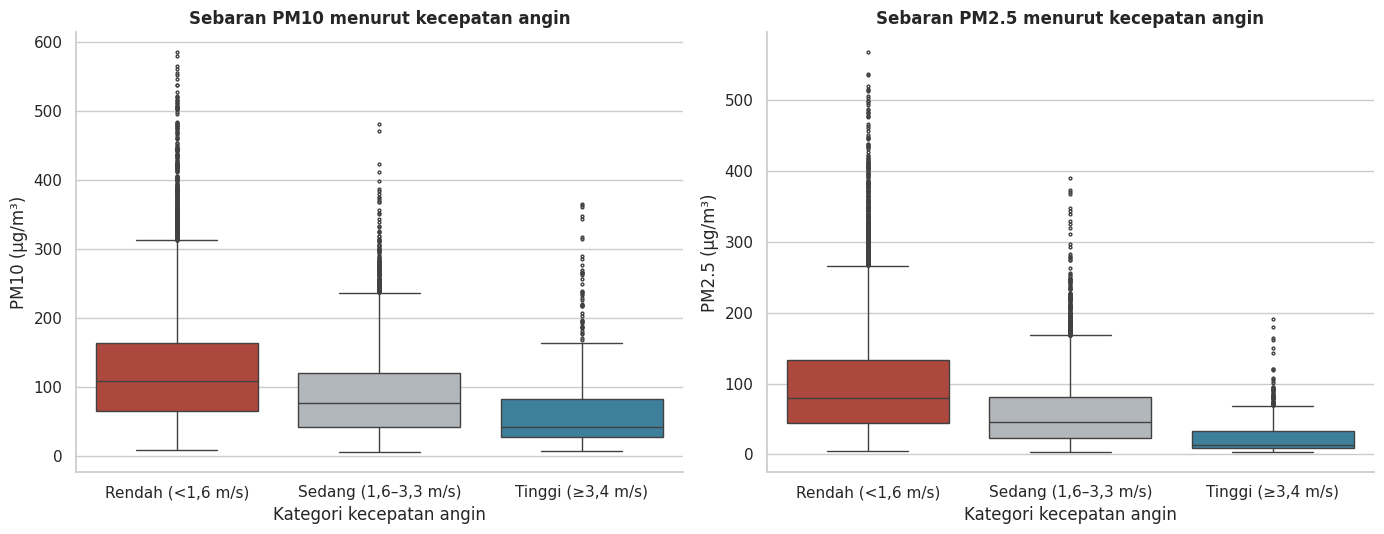

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, kol in zip(axes, ["PM10", "PM2.5"]):
    sns.boxplot(data=daily, x="kategori_angin", y=kol, order=label_angin,
                hue="kategori_angin", palette=["#C0392B", "#B0B7BD", "#2E86AB"],
                legend=False, fliersize=2, ax=ax)
    ax.set_title(f"Sebaran {kol} menurut kecepatan angin", fontweight="bold")
    ax.set_xlabel("Kategori kecepatan angin")
    ax.set_ylabel(f"{kol} (µg/m³)")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Insight:**
- Kecepatan angin berkorelasi negatif dengan PM2.5 (r = -0,38) dan PM10 (r = -0,30). Garis regresi menunjukkan setiap kenaikan 1 m/s angin berasosiasi dengan penurunan PM10 sekitar 29 µg/m³ dan PM2.5 sekitar 34 µg/m³.
- Median PM10 turun dari 108,1 µg/m³ (angin rendah) menjadi 76,6 (sedang) dan 41,8 (tinggi). Median PM2.5 turun dari 79,7 menjadi 46,0 dan 13,3. Pola ini menjadi faktor pendukung bahwa hari berangin cenderung lebih bersih.
- Kategori angin tinggi hanya berisi 772 hari-stasiun (sekitar 4%), sehingga perbandingannya paling kuat antara kategori rendah dan sedang.
- PM2.5 sangat terkait dengan PM10 (0,92), CO (0,82), dan NO2 (0,72). Variabel suhu, tekanan udara, dan titik embun saling berkorelasi kuat (misalnya suhu dan titik embun 0,90), tetapi hubungannya dengan PM2.5 lemah.
- Korelasi dan regresi menunjukkan hubungan, bukan sebab-akibat. Angin hanyalah salah satu faktor; kondisi cuaca lain dan sumber emisi juga berperan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Stasiun mana yang memiliki PM2.5 tertinggi dan terendah, dan berapa persen hari melampaui 75 µg/m³?

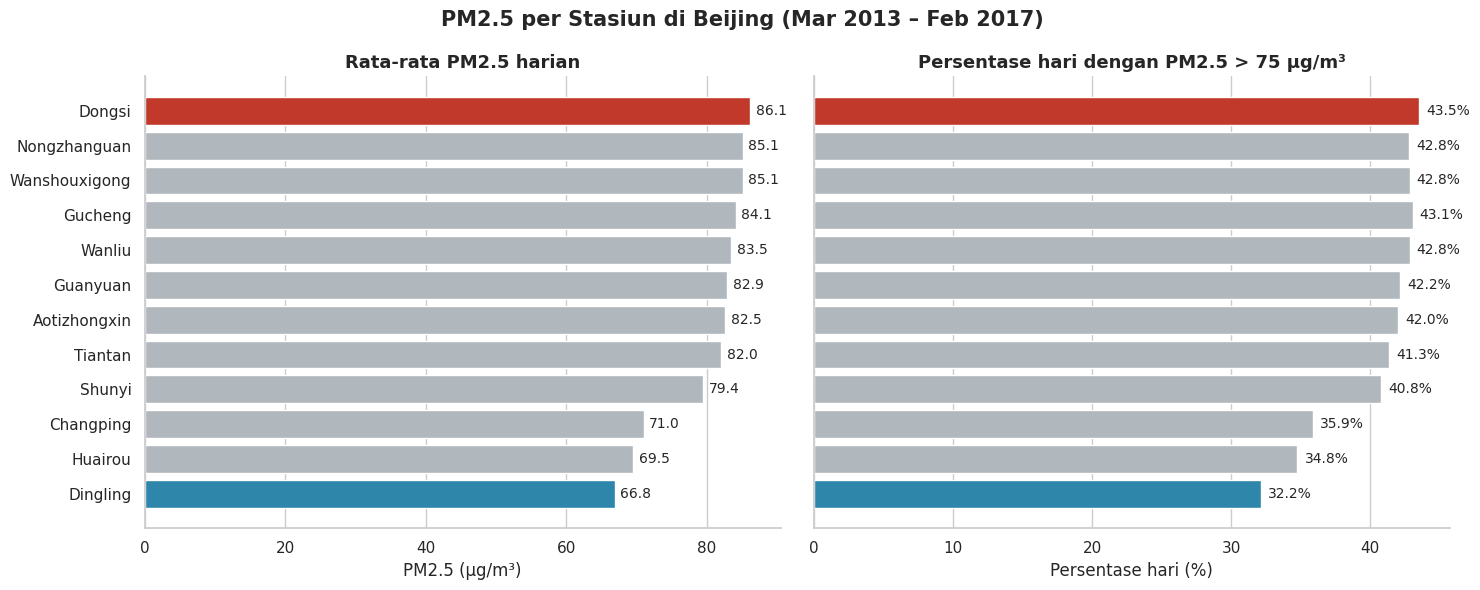

In [57]:
data_q1 = stasiun_summary.reset_index()

def warna_sorot(nilai, tertinggi, terendah):
    if nilai == tertinggi:
        return "#C0392B"   # merah: tertinggi
    if nilai == terendah:
        return "#2E86AB"   # biru: terendah
    return "#B0B7BD"       # abu-abu: lainnya

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# Panel kiri: rata-rata PM2.5
d1 = data_q1.sort_values("rata_rata_pm25", ascending=True)
w1 = [warna_sorot(v, d1["rata_rata_pm25"].max(), d1["rata_rata_pm25"].min()) for v in d1["rata_rata_pm25"]]
axes[0].barh(d1["station"], d1["rata_rata_pm25"], color=w1)
axes[0].set_title("Rata-rata PM2.5 harian", fontsize=13, fontweight="bold")
axes[0].set_xlabel("PM2.5 (µg/m³)")
for i, v in enumerate(d1["rata_rata_pm25"]):
    axes[0].text(v + 0.8, i, f"{v:.1f}", va="center", fontsize=10)

# Panel kanan: persen hari di atas 75
w2 = [warna_sorot(v, d1["persen_hari_di_atas_75"].max(), d1["persen_hari_di_atas_75"].min()) for v in d1["persen_hari_di_atas_75"]]
axes[1].barh(d1["station"], d1["persen_hari_di_atas_75"], color=w2)
axes[1].set_title("Persentase hari dengan PM2.5 > 75 µg/m³", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Persentase hari (%)")
for i, v in enumerate(d1["persen_hari_di_atas_75"]):
    axes[1].text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=10)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", visible=False)

fig.suptitle("PM2.5 per Stasiun di Beijing (Mar 2013 – Feb 2017)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- Dongsi (merah) tertinggi pada kedua ukuran: rata-rata 86,1 µg/m³ dan 43,5% hari melampaui 75 µg/m³. Dingling (biru) terendah: 66,9 µg/m³ dan 32,2% hari.
- Sembilan stasiun berada pada kisaran 79–86 µg/m³; tiga stasiun (Changping, Huairou, Dingling) jelas lebih rendah, yaitu 67–71 µg/m³.

### Pertanyaan 2: Bagaimana tren PM2.5 bulanan 2014–2016, bulan apa tertinggi, dan berapa selisih musim dingin dibandingkan musim panas?

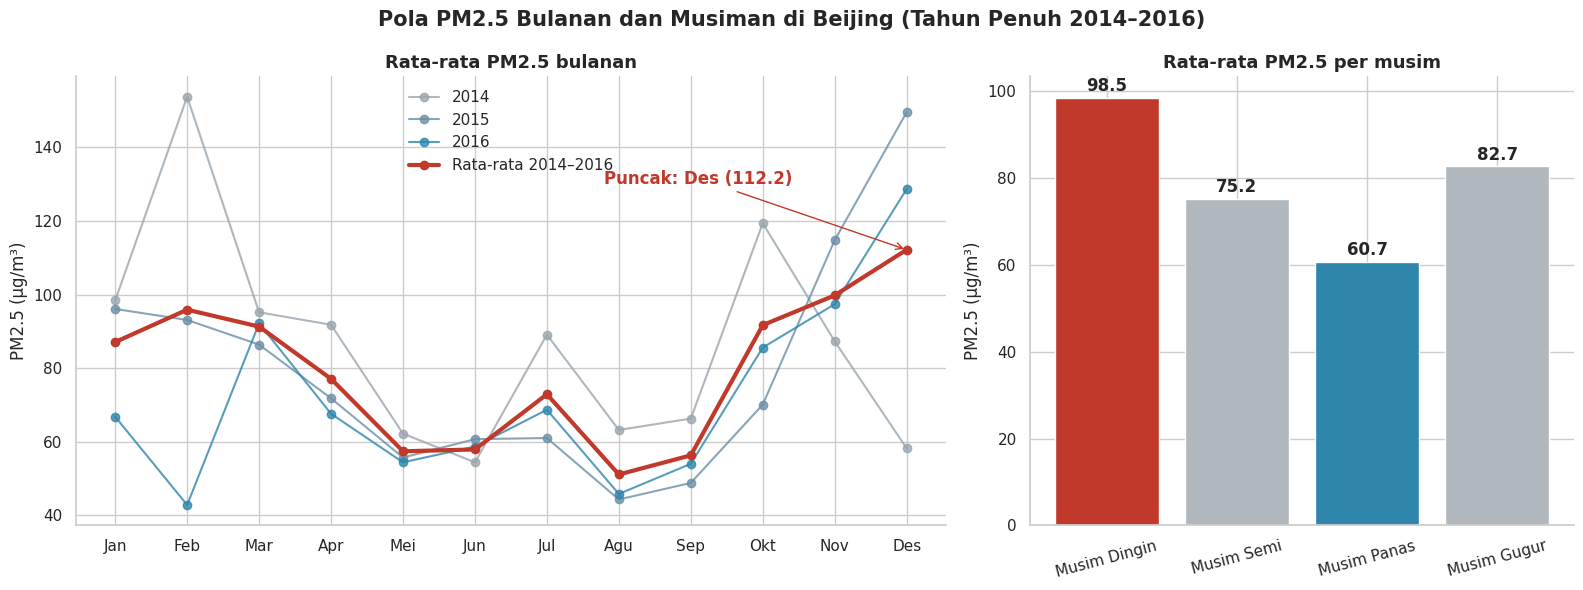

Selisih musim dingin dibandingkan musim panas: 37.8 µg/m³ (62% lebih tinggi)


In [58]:
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.6, 1]})

# Panel kiri: tren bulanan per tahun + rata-rata
warna_tahun = {2014: "#9AA5AD", 2015: "#6C8FA6", 2016: "#2E86AB"}
for tahun in [2014, 2015, 2016]:
    axes[0].plot(range(1, 13), pivot_bulan_tahun[tahun], marker="o", linewidth=1.5,
                 color=warna_tahun[tahun], alpha=0.8, label=str(tahun))
axes[0].plot(range(1, 13), bulanan.values, color="#C0392B", linewidth=3, marker="o", label="Rata-rata 2014–2016")
bulan_puncak = bulanan.idxmax()
axes[0].annotate(f"Puncak: {nama_bulan[bulan_puncak-1]} ({bulanan.max():.1f})",
                 xy=(bulan_puncak, bulanan.max()), xytext=(bulan_puncak - 4.2, bulanan.max() + 18),
                 arrowprops=dict(arrowstyle="->", color="#C0392B"), color="#C0392B", fontweight="bold")
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(nama_bulan)
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_title("Rata-rata PM2.5 bulanan", fontsize=13, fontweight="bold")
axes[0].legend(frameon=False)

# Panel kanan: rata-rata per musim
urut_musim = ["Musim Dingin", "Musim Semi", "Musim Panas", "Musim Gugur"]
nilai_musim = musiman.reindex(urut_musim)
warna_musim = ["#C0392B" if m == "Musim Dingin" else "#2E86AB" if m == "Musim Panas" else "#B0B7BD" for m in urut_musim]
axes[1].bar(urut_musim, nilai_musim.values, color=warna_musim)
for i, v in enumerate(nilai_musim.values):
    axes[1].text(i, v + 1.5, f"{v:.1f}", ha="center", fontweight="bold")
axes[1].set_title("Rata-rata PM2.5 per musim", fontsize=13, fontweight="bold")
axes[1].set_ylabel("PM2.5 (µg/m³)")
axes[1].tick_params(axis="x", rotation=15)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Pola PM2.5 Bulanan dan Musiman di Beijing (Tahun Penuh 2014–2016)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

selisih = nilai_musim["Musim Dingin"] - nilai_musim["Musim Panas"]
print(f"Selisih musim dingin dibandingkan musim panas: {selisih:.1f} µg/m³ ({selisih / nilai_musim['Musim Panas'] * 100:.0f}% lebih tinggi)")

**Insight:**
- Rata-rata bulanan tertinggi terjadi pada Desember (112,2 µg/m³), terendah pada Agustus (51,1 µg/m³).
- Musim dingin (98,5) lebih tinggi sekitar 38 µg/m³ atau sekitar 62% dibanding musim panas (60,7).
- Garis per tahun memperlihatkan variasi besar antar tahun pada bulan yang sama, tetapi pola umum musim dingin tinggi dan musim panas rendah tetap muncul.

## Analisis Lanjutan (Opsional)

### Manual Grouping & Binning: kategori kualitas udara berdasarkan PM2.5 harian

**Tujuan:** mengubah angka PM2.5 harian menjadi kategori yang mudah dipahami dengan teknik *binning*, lalu membandingkan sebaran kategori tiap musim dengan *manual grouping* (musim). Batas kategori mengikuti rentang Air Quality Index Tiongkok untuk PM2.5 rata-rata 24 jam: 0–35 Baik, 35–75 Sedang, 75–115 Tidak sehat bagi kelompok sensitif, 115–150 Tidak sehat, 150–250 Sangat tidak sehat, di atas 250 Berbahaya.

#### Membuat kategori dengan binning

In [59]:
batas = [0, 35, 75, 115, 150, 250, np.inf]
label = ["Baik", "Sedang", "Tidak sehat (sensitif)", "Tidak sehat", "Sangat tidak sehat", "Berbahaya"]
daily["kategori"] = pd.cut(daily["PM2.5"], bins=batas, labels=label)

print("Sebaran kategori seluruh hari (%):")
print((daily["kategori"].value_counts(normalize=True).reindex(label) * 100).round(1))

tabel_musim = (pd.crosstab(daily["musim"], daily["kategori"], normalize="index") * 100).reindex(urut_musim)
tabel_musim.round(1)

Sebaran kategori seluruh hari (%):
kategori
Baik                      29.5
Sedang                    30.1
Tidak sehat (sensitif)    18.2
Tidak sehat                9.5
Sangat tidak sehat         9.2
Berbahaya                  3.4
Name: proportion, dtype: float64


kategori,Baik,Sedang,Tidak sehat (sensitif),Tidak sehat,Sangat tidak sehat,Berbahaya
musim,,,,,,
Musim Dingin,31.3,23.5,14.5,9.9,13.3,7.5
Musim Semi,25.6,33.2,20.9,10.1,8.4,1.7
Musim Panas,31.6,34.2,20.2,9.7,4.1,0.2
Musim Gugur,29.8,29.3,17.3,8.3,11.0,4.3


#### Grafik batang bertumpuk

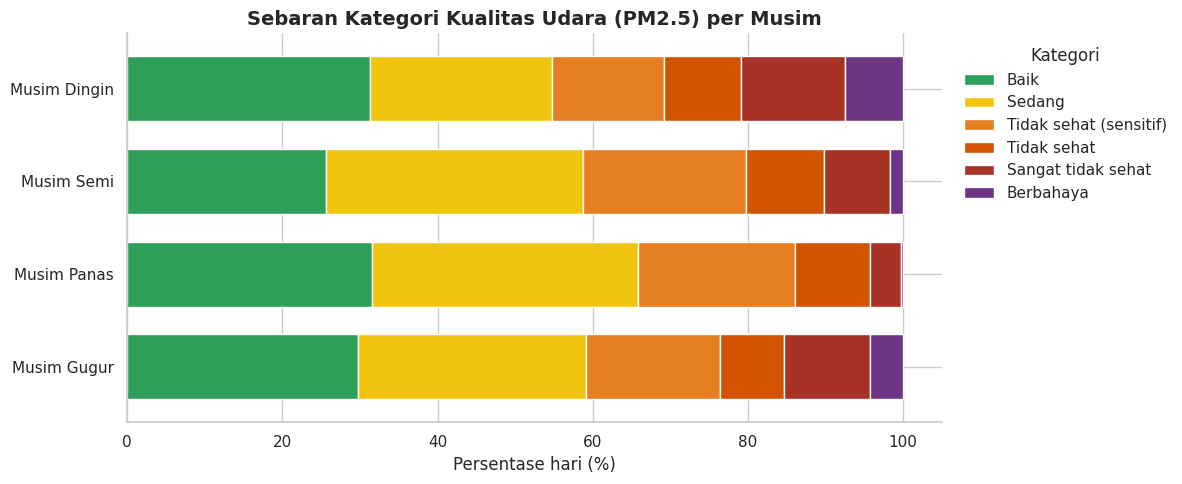

In [60]:
warna_kategori = ["#2E9E5B", "#F1C40F", "#E67E22", "#D35400", "#A93226", "#6C3483"]
ax = tabel_musim.plot(kind="barh", stacked=True, figsize=(12, 5), color=warna_kategori, width=0.7)
ax.set_xlabel("Persentase hari (%)")
ax.set_ylabel("")
ax.set_title("Sebaran Kategori Kualitas Udara (PM2.5) per Musim", fontsize=14, fontweight="bold")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Kategori", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

**Insight:**
- Hanya sekitar 29,5% hari berkategori Baik; sekitar 40% hari berada di kategori Tidak sehat (sensitif) atau lebih buruk.
- Pada musim dingin, 13,3% hari tergolong Sangat tidak sehat dan 7,5% hari Berbahaya, jauh di atas musim panas (4,1% dan 0,2%).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Stasiun **Dongsi** memiliki PM2.5 tertinggi (rata-rata 86,1 µg/m³; 43,5% hari di atas 75 µg/m³), sedangkan **Dingling** terendah (66,9 µg/m³; 32,2% hari). Sembilan stasiun berada pada kisaran 79–86 µg/m³, sementara Changping, Huairou, dan Dingling jelas lebih rendah (67–71 µg/m³). Selisih antar sembilan stasiun teratas relatif kecil, dan di semua stasiun sekitar sepertiga hari atau lebih tetap melampaui ambang 75 µg/m³.
- **Conclusion pertanyaan 2:** PM2.5 di Beijing bersifat musiman: puncaknya pada **Desember (112,2 µg/m³)** dan terendah pada **Agustus (51,1 µg/m³)**. Rata-rata musim dingin (98,5 µg/m³) sekitar 38 µg/m³ atau ±62% lebih tinggi dibanding musim panas (60,7 µg/m³). Rata-rata tahunan menurun dari 86,2 (2014) menjadi 79,3 (2015) dan 72,1 (2016), tetapi variasi antar bulan dan antar tahun masih besar. Hasil EDA juga menunjukkan bahwa kecepatan angin berkorelasi negatif dengan PM2.5 (r = -0,38): hari dengan angin rendah memiliki median PM2.5 79,7 µg/m³, sedangkan hari berangin kencang hanya 13,3 µg/m³, sehingga kondisi cuaca merupakan salah satu faktor yang perlu dipantau bersama pola musiman.

**Rekomendasi Action Item:**
- Memprioritaskan penguatan pengendalian emisi dan pemantauan di sekitar stasiun dengan PM2.5 tertinggi (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng), sambil menjadikan Dingling, Huairou, dan Changping sebagai pembanding wilayah dengan udara relatif lebih baik.
- Menyiapkan peringatan dini dan pembatasan emisi (misalnya pembatasan kendaraan atau aktivitas industri) mulai **Oktober hingga Maret**, dengan kewaspadaan tertinggi pada **November–Desember**.
- Memberikan imbauan kesehatan (misalnya memakai masker dan mengurangi aktivitas luar ruang bagi kelompok sensitif) pada hari berkategori Tidak sehat ke atas, yang jauh lebih sering terjadi di musim dingin.
- Mengevaluasi dampak kebijakan dengan data tambahan beberapa tahun ke depan, karena tren penurunan 2014–2016 baru berdasarkan tiga tahun dan masih dipengaruhi variasi cuaca.